In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [12]:
df = pd.read_csv('season-2526.csv')
home = df[['HomeTeam', 'FTHG', 'FTAG', 'HST', 'AST']].copy()
away = df[['AwayTeam', 'FTAG', 'FTHG', 'AST', 'HST']].copy()
home.columns = away.columns = ['Team', 'GF', 'GA', 'SF', 'SA']
home['Points'] = df['FTR'].map({'H': 3, 'D': 1, 'A': 0})
away['Points'] = df['FTR'].map({'H': 0, 'D': 1, 'A': 3})
games = pd.concat([home, away])
teams = games.groupby('Team')[['GF', 'GA', 'SF', 'SA']].mean()
teams['Points'] = games.groupby('Team')['Points'].sum()

In [13]:
assert len(df) == 380 and len(teams) == 20
assert (games.groupby('Team').size() == 38).all()
assert not games.isna().any().any()
assert games['GF'].sum() == games['GA'].sum()
print('Data checks passed: 380 games, 20 teams, 38 games per team.')

Data checks passed: 380 games, 20 teams, 38 games per team.


In [5]:
X = StandardScaler().fit_transform(teams[['GF', 'GA', 'SF', 'SA']])

   k  Inertia  Silhouette
0  2   41.676       0.532
1  3   21.380       0.500
2  4   14.306       0.389
3  5   10.126       0.360
4  6    8.142       0.326
5  7    6.511       0.312


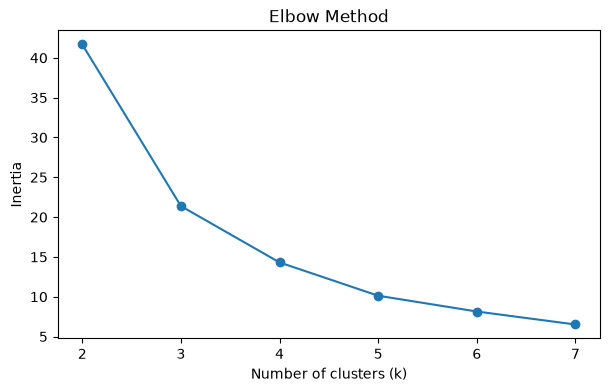

In [14]:
inertias = []
silhouettes = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=30).fit(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_))
print(pd.DataFrame({'k': range(2, 8), 'Inertia': inertias, 'Silhouette': silhouettes}).round(3))
plt.figure(figsize=(7, 4))
plt.plot(range(2, 8), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.savefig('simple_elbow.png', bbox_inches='tight')
plt.show()
plt.close()

In [15]:
teams['Cluster'] = KMeans(n_clusters=3, random_state=42, n_init=30).fit_predict(X)
averages = teams.groupby('Cluster')[['GF', 'GA']].mean()
ranked = (averages['GF'] - averages['GA']).sort_values().index
names = {ranked[0]: 'Struggling', ranked[1]: 'Middle', ranked[2]: 'Strong'}
teams['Group'] = teams['Cluster'].map(names)

print('\nTeams in each group:')
for name, group in teams.groupby('Group'):
    print(name + ':', ', '.join(group.index))
print('\nAverage statistics by group:')
print(teams.groupby('Group')[['GF', 'GA', 'SF', 'SA', 'Points']].mean().round(2))


Teams in each group:
Middle: Aston Villa, Bournemouth, Brentford, Brighton, Chelsea, Crystal Palace, Everton, Fulham, Leeds, Liverpool, Newcastle, Nott'm Forest, Sunderland, Tottenham
Strong: Arsenal, Man City, Man United
Struggling: Burnley, West Ham, Wolves

Average statistics by group:
              GF    GA    SF    SA  Points
Group                                     
Middle      1.35  1.36  4.12  4.20    51.5
Strong      1.90  0.98  5.32  3.14    78.0
Struggling  0.97  1.82  3.36  5.17    27.0


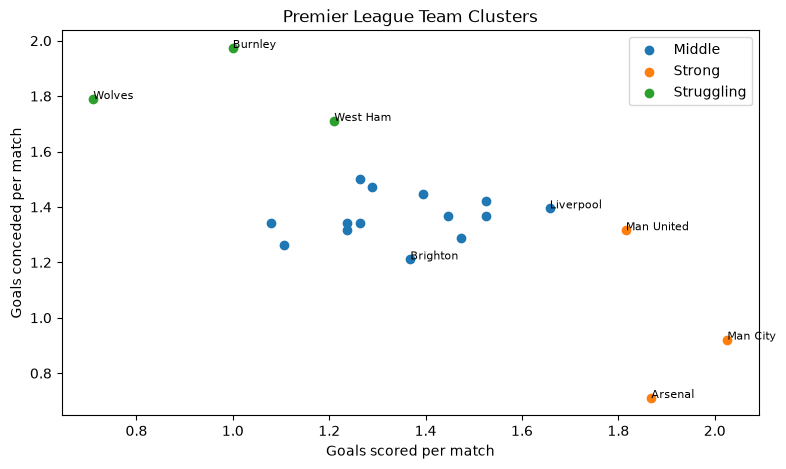

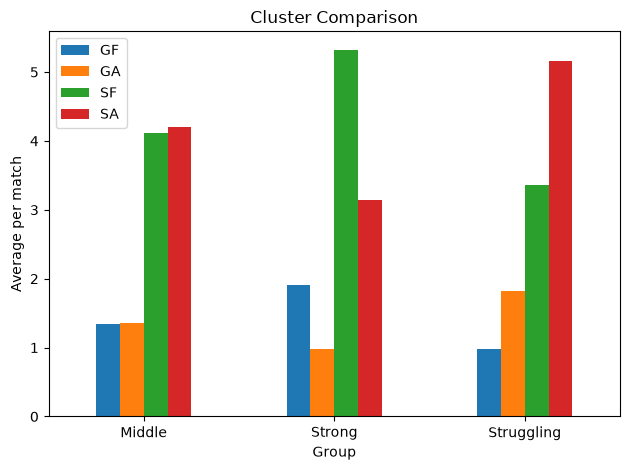

In [16]:
plt.figure(figsize=(9, 5))
for name, group in teams.groupby('Group'):
    plt.scatter(group['GF'], group['GA'], label=name)
    for team, row in group.iterrows():
        if team in ['Arsenal', 'Man City', 'Man United', 'Liverpool', 'Brighton', 'Burnley', 'West Ham', 'Wolves']:
            plt.annotate(team, (row['GF'], row['GA']), fontsize=8)
plt.xlabel('Goals scored per match')
plt.ylabel('Goals conceded per match')
plt.title('Premier League Team Clusters')
plt.legend()
plt.savefig('simple_team_clusters.png', bbox_inches='tight')
plt.show()
plt.close()

teams.groupby('Group')[['GF', 'GA', 'SF', 'SA']].mean().plot(kind='bar')
plt.ylabel('Average per match')
plt.title('Cluster Comparison')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('simple_cluster_comparison.png')
plt.show()
plt.close()

In [17]:
for seed in [0, 1, 4, 7, 12, 42]:
    repeat = KMeans(n_clusters=3, random_state=seed, n_init=30).fit_predict(X)
    print('Seed', seed, 'agreement:', round(adjusted_rand_score(teams['Cluster'], repeat), 3))
teams.to_csv('simple_team_results.csv')

Seed 0 agreement: 1.0
Seed 1 agreement: 1.0
Seed 4 agreement: 1.0
Seed 7 agreement: 1.0
Seed 12 agreement: 1.0
Seed 42 agreement: 1.0
